# Dataset 2: Netflix Movies and TV Shows - Data Cleaning & Visualization

* **Kaggle Link:** [Netflix Movies and TV Shows on Kaggle](https://www.kaggle.com/datasets/shivamb/netflix-shows)
* **Core Competencies:** Datetime parsing, string cleaning, array flattening/exploding, frequency distributions, and data visualization.

This notebook performs basic data cleaning and exploratory data analysis on the Netflix dataset, covering missing value handling, datetime parsing, duration extraction, genre analysis, and various visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('fivethirtyeight')
sns.set_style('whitegrid')

netflix_path = 'netflix_titles.csv'
df = pd.read_csv(netflix_path)

print('Shape of the dataset:', df.shape)
print('Column names:', list(df.columns))
print('\nFirst 5 rows:')
display(df.head())
print('\nData types:')
display(df.dtypes)

Shape of the dataset: (8807, 12)
Column names: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

First 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Data types:


show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

## 1. Data Exploration & Basic Cleaning

### 1.1 Check for missing values

Let's examine which columns have missing values and how many.

Columns with missing values:


,Total Missing,Percentage
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


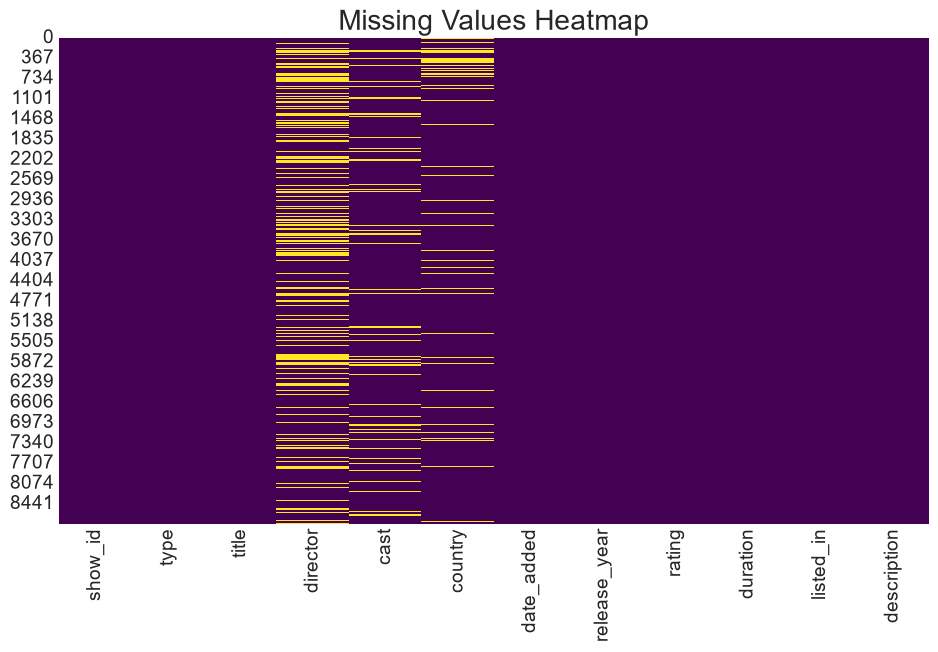

In [2]:
# Check for missing values in each column
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Total Missing': missing_values,
    'Percentage': missing_percent.round(2)
})

missing_df = missing_df[missing_df['Total Missing'] > 0].sort_values('Total Missing', ascending=False)
print('Columns with missing values:')
display(missing_df)

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

### 1.2 Impute missing values

We'll impute missing `director` and `cast` values with 'Unknown', and drop rows where `date_added` or `rating` is missing.

In [3]:
# Impute missing director and cast with 'Unknown'
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')

# Drop rows where date_added or rating is missing
df = df.dropna(subset=['date_added', 'rating'])

# Verify missing values after cleaning
missing_after = df.isnull().sum()
missing_after_df = pd.DataFrame({
    'Total Missing': missing_after,
    'Percentage': (missing_after / len(df)) * 100
})
missing_after_df = missing_after_df[missing_after_df['Total Missing'] > 0]
print('Remaining missing values after cleaning:')
display(missing_after_df)

print(f'\nDataset shape after cleaning: {df.shape}')

Remaining missing values after cleaning:


,Total Missing,Percentage
country,829,9.427954
duration,3,0.034118



Dataset shape after cleaning: (8793, 12)


## 2. Datetime Parsing & Temporal Analysis

### 2.1 Parse `date_added` and extract temporal features

We need to strip whitespace and convert `date_added` to pandas datetime, then extract `added_year`, `added_month_name`, and `added_day_name`.

In [4]:
# 1. Strip whitespace and convert to datetime
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())

# 2. Extract temporal features
df['added_year'] = df['date_added'].dt.year
df['added_month'] = df['date_added'].dt.month
df['added_month_name'] = df['date_added'].dt.month_name()
df['added_day_name'] = df['date_added'].dt.day_name()

# Display the new columns
print('Sample of new temporal columns:')
display(df[['title', 'date_added', 'added_year', 'added_month_name', 'added_day_name']].head(10))

Sample of new temporal columns:


,title,date_added,added_year,added_month_name,added_day_name
0,Dick Johnson Is Dead,2021-09-25,2021,September,Saturday
1,Blood & Water,2021-09-24,2021,September,Friday
2,Ganglands,2021-09-24,2021,September,Friday
3,Jailbirds New Orleans,2021-09-24,2021,September,Friday
4,Kota Factory,2021-09-24,2021,September,Friday
5,Midnight Mass,2021-09-24,2021,September,Friday
6,My Little Pony: A New Generation,2021-09-24,2021,September,Friday
7,Sankofa,2021-09-24,2021,September,Friday
8,The Great British Baking Show,2021-09-24,2021,September,Friday
9,The Starling,2021-09-24,2021,September,Friday


Top 10 months with most titles added:


added_month_name
July         827
December     812
September    770
April        764
October      760
August       755
March        741
January      737
June         728
November     705
Name: count, dtype: int64

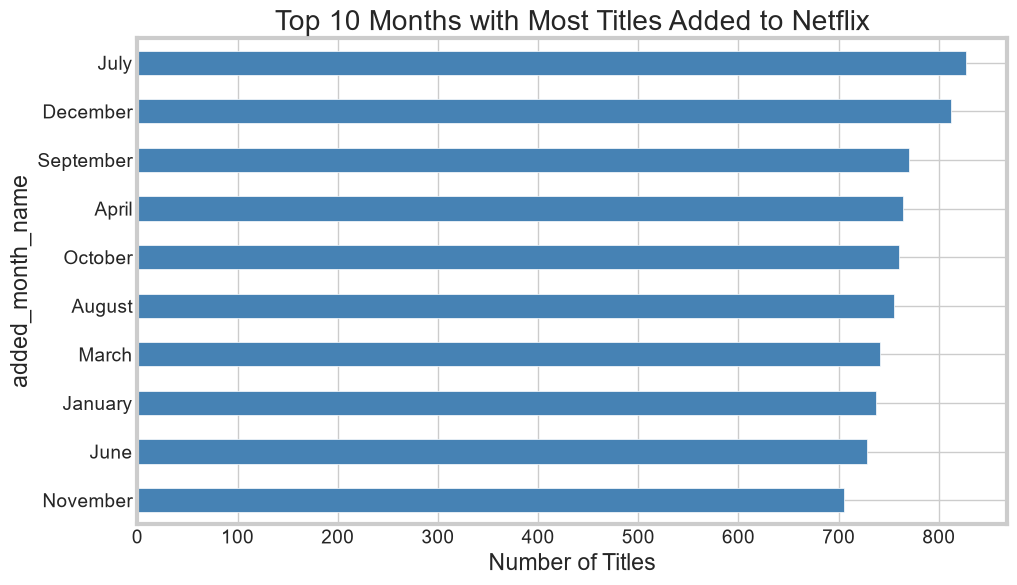

In [5]:
# 3. Identify top 3 months with most titles added
top_months = df['added_month_name'].value_counts().head(10)
print('Top 10 months with most titles added:')
display(top_months)

plt.figure(figsize=(10, 6))
top_months.plot(kind='barh', color='steelblue')
plt.title('Top 10 Months with Most Titles Added to Netflix')
plt.xlabel('Number of Titles')
plt.gca().invert_yaxis()
plt.show()

## 3. Numeric Duration Extraction

### 3.1 Parse duration for movies and TV shows

For movies, extract the minute count from the `duration` column (e.g., '90 min' -> 90). For TV shows, extract the season count into a new `seasons` column.

Movie durations summary statistics:


<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_7764\1818915673.py:4: SyntaxWarning: invalid escape sequence '\d'
  df.loc[movie_mask, 'duration_minutes'] = df.loc[movie_mask, 'duration_clean'].str.extract('(\d+)').astype(float)
C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_7764\1818915673.py:6: SyntaxWarning: invalid escape sequence '\d'
  df.loc[~movie_mask, 'seasons'] = df.loc[~movie_mask, 'duration_clean'].str.extract('(\d+)').astype(float)


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: duration_minutes, dtype: float64

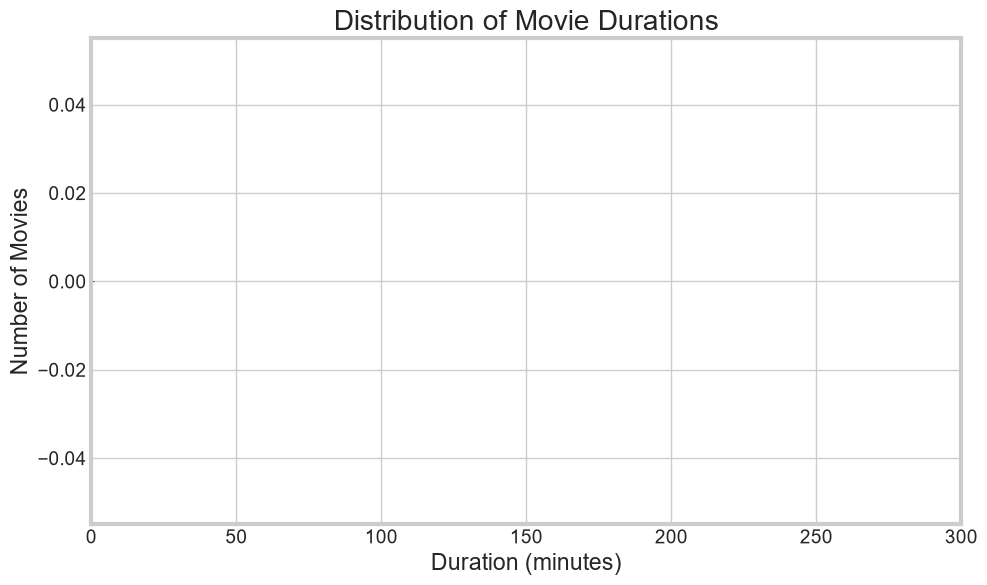

In [6]:
df['duration_clean'] = df['duration'].astype(str)

movie_mask = df['type'] == 'Movie'
df.loc[movie_mask, 'duration_minutes'] = df.loc[movie_mask, 'duration_clean'].str.extract('(\d+)').astype(float)

df.loc[~movie_mask, 'seasons'] = df.loc[~movie_mask, 'duration_clean'].str.extract('(\d+)').astype(float)

movie_durations = df[movie_mask]['duration_minutes'].dropna()
print('Movie durations summary statistics:')
display(movie_durations.describe())

plt.figure(figsize=(10, 6))
plt.hist(movie_durations, bins=30, color='darkorange', edgecolor='black')
plt.title('Distribution of Movie Durations')
plt.xlabel('Duration (minutes)')
plt.ylabel('Number of Movies')
plt.xlim(0, 300)
plt.show()

## 4. Duration Bins with `np.select`

### 4.1 Categorize movie durations using `np.select`

Categorize movie durations into 'Short' (< 60 min), 'Feature' (60-120 min), and 'Long' (> 120 min). Calculate the percentage share of each category.

Movie Duration Categories:


duration_category
Unknown    6129
Name: count, dtype: int64


Percentage share:


duration_category
Unknown    100.0
Name: count, dtype: float64

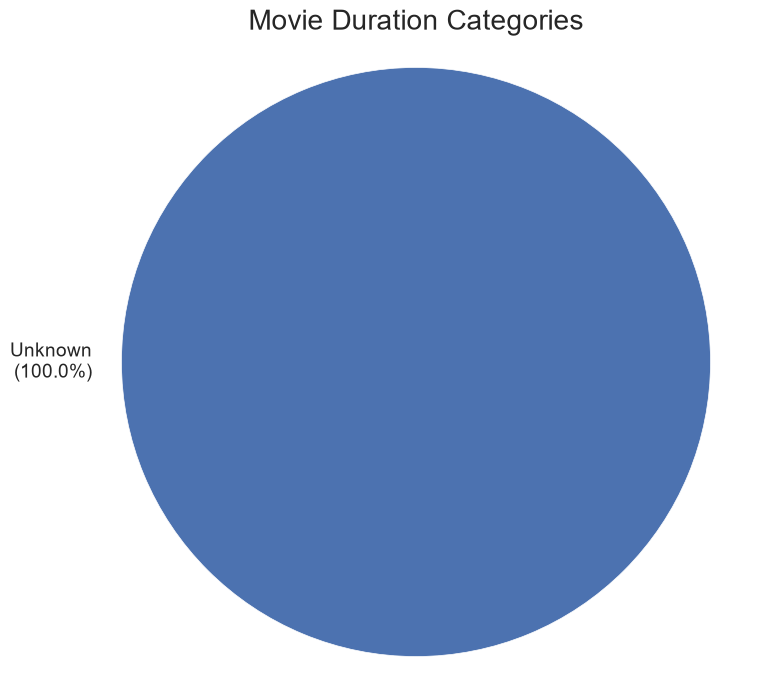

In [7]:
conditions = [
    df.loc[movie_mask, 'duration_minutes'] < 60,
    (df.loc[movie_mask, 'duration_minutes'] >= 60) & (df.loc[movie_mask, 'duration_minutes'] <= 120),
    df.loc[movie_mask, 'duration_minutes'] > 120
]

choices = ['Short', 'Feature', 'Long']

movie_df = df[movie_mask].copy()
movie_df['duration_category'] = np.select(conditions, choices, default='Unknown')

duration_counts = movie_df['duration_category'].value_counts()
duration_percent = (duration_counts / len(movie_df) * 100).round(1)

print('Movie Duration Categories:')
display(duration_counts)
print('\nPercentage share:')
display(duration_percent)

plt.figure(figsize=(8, 8))
labels = [f'{cat}\n({pct}%)' for cat, pct in zip(duration_counts.index, duration_percent)]
plt.pie(duration_counts, labels=labels, autopct='', colors=['#4c72b0', '#55a868', '#c44e52'])
plt.title('Movie Duration Categories')
plt.axis('equal')
plt.show()

## 5. Exploding Delimited Strings (Countries)

### 5.1 Split comma-separated strings in `country` and find top 10 contributing countries

Use `.explode()` to create a flat series where each row has a single country, strip whitespace, and determine the top 10 countries.

Top 10 Countries:


country_list
United States     3684
India             1046
United Kingdom     805
Canada             445
France             393
Japan              316
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

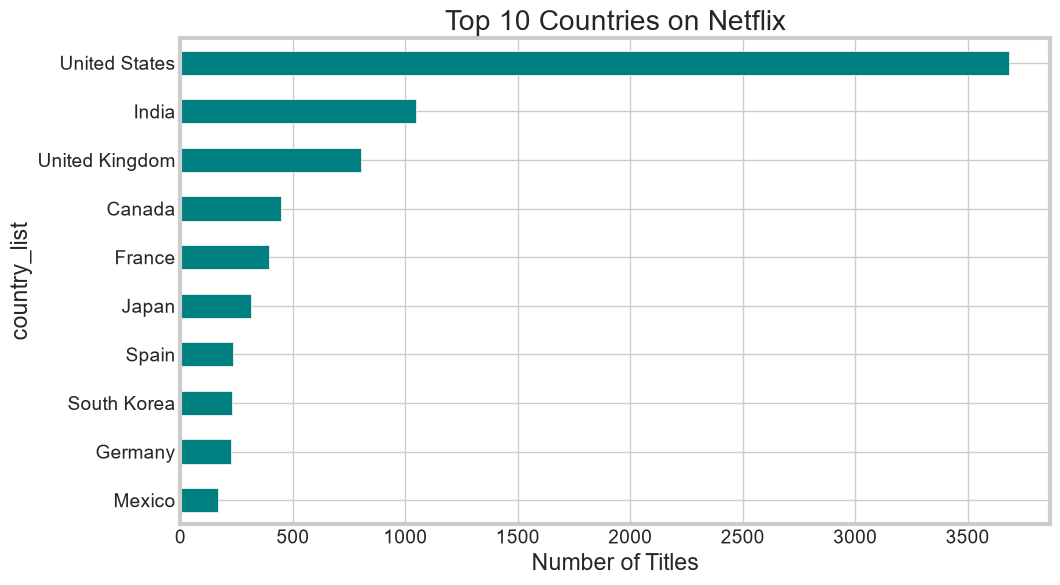

In [8]:
df['country_list'] = df['country'].astype(str).str.split(',')

country_exploded = df['country_list'].explode()

country_counts = country_exploded.str.strip().value_counts().head(10)

print('Top 10 Countries:')
display(country_counts)

plt.figure(figsize=(10, 6))
country_counts.plot(kind='barh', color='teal')
plt.title('Top 10 Countries on Netflix')
plt.xlabel('Number of Titles')
plt.gca().invert_yaxis()
plt.show()

## 6. Genre Intersection Filtering

### 6.1 Filter titles under both 'Documentaries' AND 'International Movies' released between 2018-2022

Find titles that fall simultaneously under both genres and were released 2018-2022 (inclusive). Return title, director, and release year.

In [9]:
df['listed_in_list'] = df['listed_in'].astype(str).str.split(',')
df_exploded = df.explode('listed_in_list')

doc_intl_mask = df_exploded['listed_in_list'].str.strip().isin(['Documentaries', 'International Movies'])
doc_intl_titles = df_exploded[doc_intl_mask]

doc_intl_filtered = doc_intl_titles[doc_intl_titles['release_year'].between(2018, 2022)]

result = doc_intl_filtered[['title', 'director', 'release_year']].drop_duplicates()

print(f'Found {len(result)} titles matching the criteria:')
display(result.head(20))

Found 1232 titles matching the criteria:


,title,director,release_year
0,Dick Johnson Is Dead,Kirsten Johnson,2020
12,Je Suis Karl,Christian Schwochow,2021
16,Europe's Most Dangerous Man: Otto Skorzeny in ...,"Pedro de Echave García, Pablo Azorín Williams",2020
30,Ankahi Kahaniya,"Ashwiny Iyer Tiwari, Abhishek Chaubey, Saket C...",2021
35,The Father Who Moves Mountains,Daniel Sandu,2021
36,The Stronghold,Cédric Jimenez,2021
45,My Heroes Were Cowboys,Tyler Greco,2021
68,Schumacher,"Hanns-Bruno Kammertöns, Vanessa Nöcker, Michae...",2021
73,King of Boys,Kemi Adetiba,2018
78,Tughlaq Durbar,Delhiprasad Deenadayalan,2020


## 7. Cast Frequency Ranking

### 7.1 Split and explode the `cast` column, filter out 'Unknown', and find top 10 most frequently credited actors

Explode the cast column to get individual actors, then count their frequencies.

Top 10 Most Frequently Credited Actors:


cast_list
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64

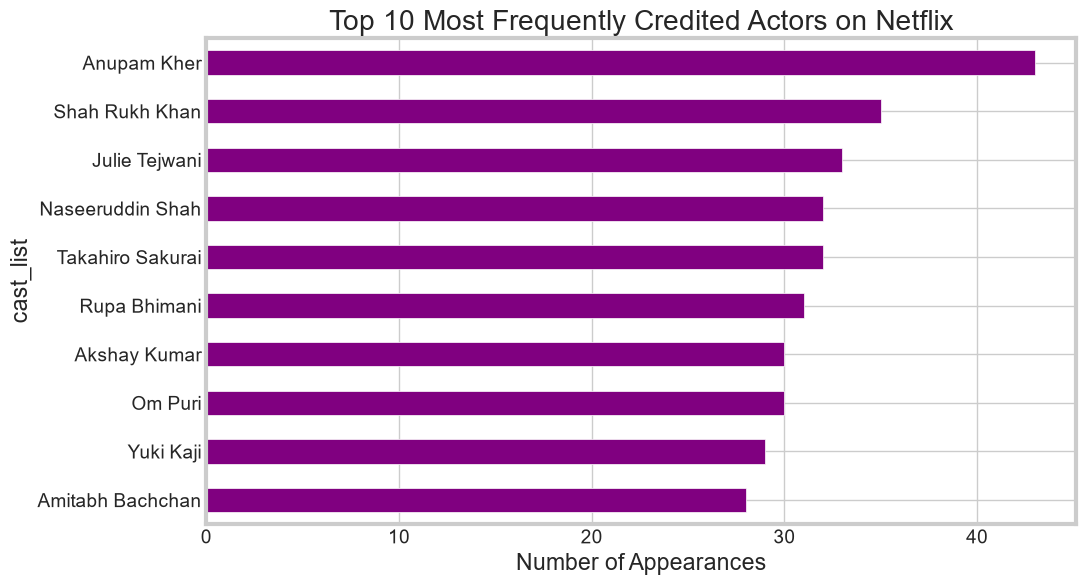

In [10]:
df['cast_list'] = df['cast'].astype(str).str.split(',')
cast_exploded = df['cast_list'].explode()

cast_clean = cast_exploded.str.strip()
cast_clean = cast_clean[cast_clean != 'Unknown']

top_actors = cast_clean.value_counts().head(10)

print('Top 10 Most Frequently Credited Actors:')
display(top_actors)

plt.figure(figsize=(10, 6))
top_actors.plot(kind='barh', color='purple')
plt.title('Top 10 Most Frequently Credited Actors on Netflix')
plt.xlabel('Number of Appearances')
plt.gca().invert_yaxis()
plt.show()

## 8. Decade Aggregation with NumPy Floor Division

### 8.1 Create a `decade` column using integer floor division: `(release_year // 10) * 10`

Compute the count and ratio of TV Shows to Movies produced in each decade.

Movies vs TV Shows per decade:


type,Movie,TV Show,ratio
decade,,,
1920,0,1,0.000000
1940,13,2,6.500000
1950,11,0,inf
1960,23,2,11.500000
1970,66,4,16.500000
1980,122,7,17.428571
1990,241,33,7.303030
2000,677,130,5.207692
2010,4182,1734,2.411765


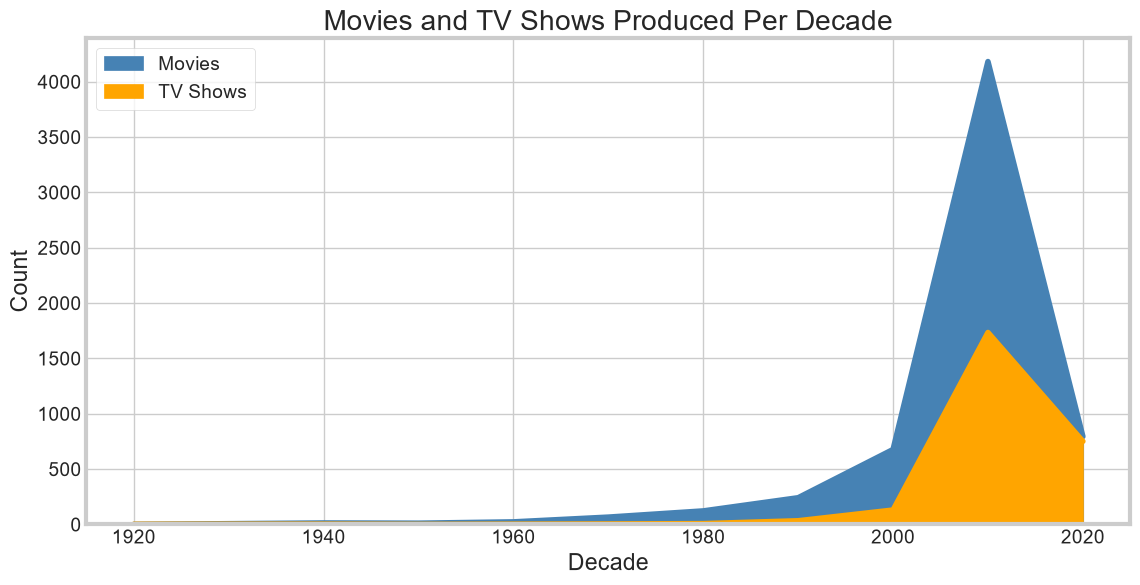

In [11]:
df['decade'] = (df['release_year'] // 10) * 10

decade_type_counts = df.groupby(['decade', 'type']).size().unstack(fill_value=0)

decade_type_counts['ratio'] = decade_type_counts['Movie'] / decade_type_counts['TV Show']

print('Movies vs TV Shows per decade:')
display(decade_type_counts)

decade_type_counts['Movie'].plot(kind='area', figsize=(12, 6), color='steelblue', label='Movies')
decade_type_counts['TV Show'].plot(kind='area', figsize=(12, 6), color='orange', label='TV Shows')
plt.title('Movies and TV Shows Produced Per Decade')
plt.xlabel('Decade')
plt.ylabel('Count')
plt.legend()
plt.show()

## 9. Contingency Matrix (`pd.crosstab`) to NumPy Array

### 9.1 Generate a cross-tabulation table between `rating` (rows) and `type` (columns)

Convert this contingency table into a pure 2D NumPy array matrix for downstream numerical or Chi-squared testing.

In [12]:
ct = pd.crosstab(df['rating'], df['type'])

print('Contingency Table (Rating vs Type):')
display(ct)

ct_array = ct.to_numpy()
print('\nAs NumPy array:')
print(ct_array)
print(f'\nShape: {ct_array.shape}')

Contingency Table (Rating vs Type):


type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2



As NumPy array:
[[   1    0]
 [   1    0]
 [   1    0]
 [  41    0]
 [   3    0]
 [  75    4]
 [ 287    0]
 [ 490    0]
 [ 797    2]
 [1427  730]
 [ 126   94]
 [2062 1143]
 [ 540  321]
 [ 131  175]
 [ 139  194]
 [   5    1]
 [   3    0]]

Shape: (17, 2)


## 10. Text Length Quantiles with NumPy

### 10.1 Compute the word count of each title's `description`

Using `np.quantile()`, calculate the 25th, 50th (median), 75th, 90th, and 99th percentiles of description lengths.

Description Length Quantiles:
  25.0th percentile: 22.0 words
  50.0th percentile: 24.0 words
  75.0th percentile: 26.0 words
  90.0th percentile: 27.0 words
  99.0th percentile: 30.0 words


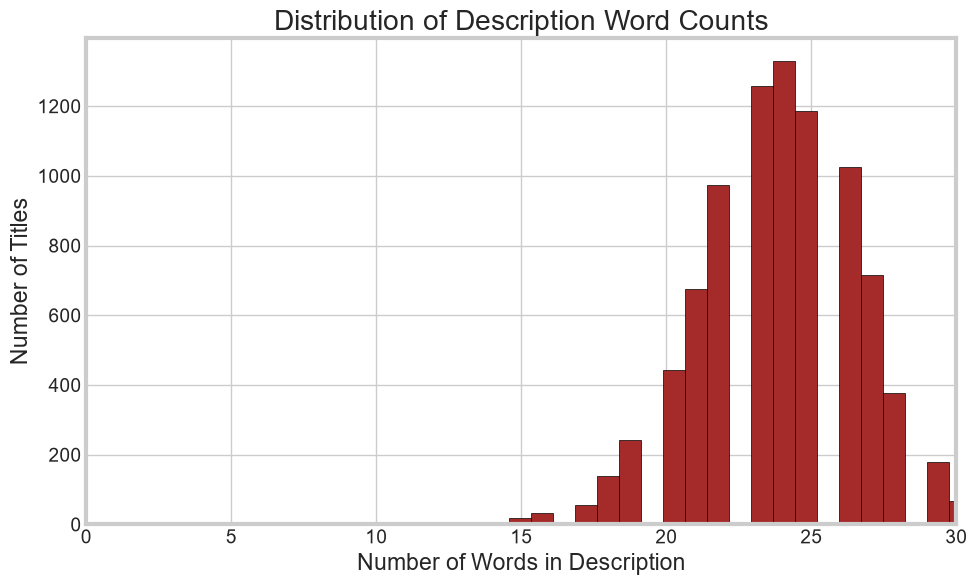

In [13]:
df['description_word_count'] = df['description'].astype(str).str.split().apply(len)

quantiles = [0.25, 0.50, 0.75, 0.90, 0.99]
quantile_values = np.quantile(df["description_word_count"], quantiles)

print('Description Length Quantiles:')
for q, v in zip(quantiles, quantile_values):
    print(f'  {q*100}th percentile: {v:.1f} words')

plt.figure(figsize=(10, 6))
plt.hist(df['description_word_count'], bins=50, color='brown', edgecolor='black')
plt.title('Distribution of Description Word Counts')
plt.xlabel('Number of Words in Description')
plt.ylabel('Number of Titles')
plt.xlim(0, df['description_word_count'].quantile(0.99))
plt.show()

## Summary & Best Practices

- **NumPy** excels at fast, low-level array transformations, mathematical vectorization (`np.where`, `np.select`, `np.log1p`), and percentile calculations.
- **Pandas** excels at labeled data wrangling, grouping (`groupby`, `pivot_table`), datetime manipulation, and string processing.
- Keep data types clean and always handle edge cases (like division by zero, skewness, and group-level missingness) before feeding data into downstream machine learning pipelines.
- Visualizations should be clear, labeled, and use consistent styling for readability.